In [54]:
from langgraph.graph import StateGraph,START,END
from typing import TypedDict,Literal


In [55]:
#1st step is to create a state

class Quadstate(TypedDict):
    a:int
    b:int
    c:int
    equation:str
    discriminant:float
    result:str

    

In [56]:
def show_equation(state:Quadstate):
    equation=f"{state['a']}x2 + {state['b']}x + {state['c']}"
    return {"equation":equation}

def calculate_discriment(state:Quadstate):
   discriminant= state['b']**2 - (4*state['a']*state['c'])
   return {'discriminant':discriminant}


In [57]:
def real_root(state:Quadstate):
    return {"result":"Two real root"}
def repeated_root(state:Quadstate):
    return {"result":"Two equal root"}

def no_real_root(state:Quadstate):
    return {'result':"NO real root"}
    


def check_condition(state:Quadstate)->Literal['real_root','repeated_root','no_real_root']:
    if state['discriminant']>0:
        return 'real_root'
    elif state['discriminant']==0:
        return 'repeated_root'
    else:
        return 'no_real_root'


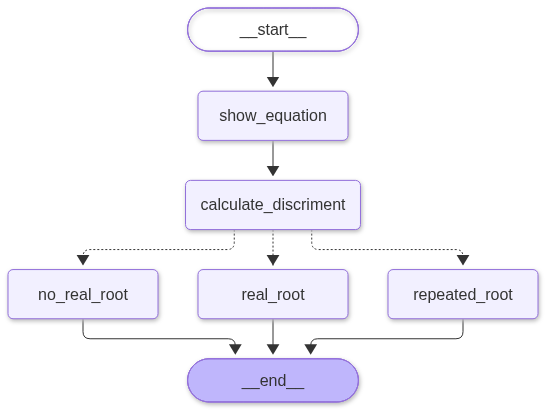

In [60]:
graph=StateGraph(Quadstate)
graph.add_node("show_equation",show_equation)
graph.add_node("calculate_discriment",calculate_discriment)
graph.add_node("real_root",real_root)
graph.add_node("repeated_root",repeated_root)
graph.add_node("no_real_root",no_real_root)



graph.add_edge(START,"show_equation")
graph.add_edge("show_equation","calculate_discriment")
graph.add_conditional_edges('calculate_discriment',check_condition)
graph.add_edge("real_root",END)
graph.add_edge("repeated_root",END)
graph.add_edge("no_real_root",END)
graph.compile()


In [59]:
initial_state={
    'a':4,
    'b':-5,
    'c':-4
}

workflow.invoke(initial_state)

{'a': 4,
 'b': -5,
 'c': -4,
 'equation': '4x2 + -5x + -4',
 'discriminant': 89,
 'result': 'Two real root'}